# Análise exploratória do dataset

Este notebook examina a versão 1 do dataset (`dataset/v1/dataset.csv`), gerada a partir do cenário `evento_termico_v1`
(ver `cenarios/v1/`). A comparação com a versão 2 está em `03_comparacao_versoes.ipynb`.
O objetivo é entender os dados **antes** de treinar modelos:

1. leitura e conferência do arquivo;
2. tipos, valores ausentes e o que eles significam;
3. quantidade de exemplos por classe;
4. comportamento de temperatura, pressão, bateria e rede ao longo do ciclo;
5. distribuição dos atributos por classe e correlações;
6. implicações para o pré-processamento e a modelagem (notebook `02_modelos_iniciais.ipynb`).

Cada linha do CSV é **uma tentativa de consulta CoAP** a um dos dez sensores. O rótulo `label` é a fase global do
ambiente no instante de envio, atribuída pelo cronograma (ver `cenarios/rotulacao.md`), e não por limiares sobre as leituras.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from comum import (CLASSES, NOMES_CLASSES, ORDEM_PAPEIS, COR_CLASSE, COR_PAPEL, SENSORES, BATERIA, REDE,
                   TEXTO_SEC, aplicar_estilo, carregar_dados, salvar, sombrear_fases)

aplicar_estilo()
pd.set_option("display.precision", 2)
pd.set_option("display.width", 120)

## 1. Leitura e conferência

A leitura segue `dataset/dicionario_dados.md`: os tempos em nanossegundos ficam como inteiros, e campos vazios
continuam ausentes (não viram zero). Primeiro carregamos o arquivo completo, inclusive as respostas que cruzaram
uma fronteira de fase, para conferir as contagens publicadas em `dataset/README.md`.

In [2]:
bruto = carregar_dados(incluir_cruzamentos=True)
print(f"Linhas: {len(bruto)} | colunas: {bruto.shape[1] - 1} (+ coluna auxiliar 'papel')")
print(f"Execuções: {bruto['run_id'].nunique()} | dispositivos: {bruto['device_id'].nunique()} | gateways: {bruto['gateway_id'].nunique()}")
print(f"Linhas duplicadas: {bruto.drop(columns='papel').duplicated().sum()}")
print(f"Respostas que cruzaram fase (cruzou_fase = 1): {bruto['cruzou_fase'].sum()}")
print(f"elapsed_s de {bruto['elapsed_s'].min():.2f} a {bruto['elapsed_s'].max():.2f} s")

Linhas: 2062 | colunas: 26 (+ coluna auxiliar 'papel')
Execuções: 1 | dispositivos: 10 | gateways: 2
Linhas duplicadas: 0
Respostas que cruzaram fase (cruzou_fase = 1): 2
elapsed_s de 0.23 a 1199.12 s


In [3]:
# Confere se o rótulo corresponde exatamente ao intervalo temporal de envio.
limites = bruto.groupby("label", observed=True)["elapsed_s"].agg(["min", "max", "count"])
limites

,min,max,count
label,,,
normal,0.23,299.56,586
pre_desastre,300.50,599.83,539
desastre,600.76,899.94,436
pos_desastre,900.91,1199.12,501


Seguindo `cenarios/rotulacao.md`, as duas respostas válidas que atravessaram uma fronteira de fase são removidas da
análise supervisionada. O restante da análise usa esse conjunto.

In [4]:
dados = carregar_dados()
print(f"Linhas usadas: {len(dados)}")
dados.head()

Linhas usadas: 2060


,timestamp,run_id,device_id,gateway_id,latitude,longitude,temperature,pressure,battery,battery_rate_pp_min,...,device_role,scenario_id,label,elapsed_s,sent_time_ns,receipt_time_ns,message_id,em_transicao,cruzou_fase,papel
0,2026-10-15 16:29:52.093062+00:00,execucao-1792081791860377862,gw02-d01,gw02,-18.92,-48.27,23.37,1009.68,99.97,NaN,...,falha_energetica,evento_termico_v1,normal,0.23,1792081792093062082,1792081792198361747,3,0,0,Falha energética
1,2026-10-15 16:29:52.106793+00:00,execucao-1792081791860377862,gw01-d03,gw01,-18.92,-48.28,22.14,1008.37,95.97,NaN,...,degradacao,evento_termico_v1,normal,0.25,1792081792106793541,1792081792219419473,3,0,0,Degradação
2,2026-10-15 16:29:53.091824+00:00,execucao-1792081791860377862,gw02-d02,gw02,-18.92,-48.27,29.64,1016.23,97.97,NaN,...,falha_rede,evento_termico_v1,normal,1.23,1792081793091824469,1792081793199847336,3,0,0,Falha de rede
3,2026-10-15 16:29:53.112480+00:00,execucao-1792081791860377862,gw01-d04,gw01,-18.92,-48.28,20.83,1005.46,93.97,NaN,...,degradacao,evento_termico_v1,normal,1.25,1792081793112480045,1792081793219086032,3,0,0,Degradação
4,2026-10-15 16:29:54.096847+00:00,execucao-1792081791860377862,gw02-d03,gw02,-18.92,-48.27,24.61,1011.80,95.97,NaN,...,degradacao,evento_termico_v1,normal,2.24,1792081794096847266,1792081794135282264,3,0,0,Degradação


## 2. Tipos e valores ausentes

In [5]:
dados.dtypes.to_frame("tipo").T

,timestamp,run_id,device_id,gateway_id,latitude,longitude,temperature,pressure,battery,battery_rate_pp_min,...,device_role,scenario_id,label,elapsed_s,sent_time_ns,receipt_time_ns,message_id,em_transicao,cruzou_fase,papel
tipo,"datetime64[us, UTC]",str,str,str,float64,float64,float64,float64,float64,float64,...,str,str,category,float64,Int64,Int64,int64,int64,int64,str


In [6]:
ausentes = dados.isna().sum()
ausentes[ausentes > 0].to_frame("ausentes").assign(percentual=lambda t: 100 * t["ausentes"] / len(dados))

,ausentes,percentual
temperature,365,17.72
pressure,365,17.72
battery,365,17.72
battery_rate_pp_min,463,22.48
latency_ms,365,17.72
error,1695,82.28
receipt_time_ns,365,17.72


Os ausentes de `temperature`, `pressure`, `battery` e `latency_ms` coincidem exatamente com as tentativas sem
resposta válida (`available = 0`). Eles **não são ausentes ao acaso**: dependem do estado da rede e da bateria e,
portanto, da fase. `error` vazio indica sucesso, e `sem_resposta` reúne timeouts e respostas `5.03` de sensores
sem bateria, que o CSV do gateway não distingue.

In [7]:
medicoes = ["temperature", "pressure", "battery", "latency_ms"]
assert (dados[medicoes].isna().all(axis=1) == (dados["available"] == 0)).all()
assert (dados[medicoes].notna().all(axis=1) == (dados["available"] == 1)).all()
pd.crosstab(dados["label"], dados["error"].fillna("(sucesso)"), margins=True, margins_name="Total")

error,(sucesso),sem_resposta,Total
label,,,
normal,579,7,586
pre_desastre,505,33,538
desastre,277,158,435
pos_desastre,334,167,501
Total,1695,365,2060


## 3. Quantidade de exemplos por classe

As quatro fases têm a mesma duração (300 s), mas não o mesmo número de linhas: um timeout prende o sensor por até
15 s, reduzindo o número de tentativas durante a degradação.

In [8]:
contagem = (dados.groupby("label", observed=True)
            .agg(tentativas=("label", "size"), com_medicoes=("available", "sum"))
            .assign(sem_medicoes=lambda t: t["tentativas"] - t["com_medicoes"],
                    percentual=lambda t: 100 * t["tentativas"] / t["tentativas"].sum(),
                    disponibilidade=lambda t: 100 * t["com_medicoes"] / t["tentativas"]))
contagem.loc["Total"] = contagem.sum()
contagem.loc["Total", "disponibilidade"] = 100 * contagem.loc["Total", "com_medicoes"] / contagem.loc["Total", "tentativas"]
contagem.astype({"tentativas": int, "com_medicoes": int, "sem_medicoes": int})

,tentativas,com_medicoes,sem_medicoes,percentual,disponibilidade
label,,,,,
normal,586,579,7,28.45,98.81
pre_desastre,538,505,33,26.12,93.87
desastre,435,277,158,21.12,63.68
pos_desastre,501,334,167,24.32,66.67
Total,2060,1695,365,100.00,82.28


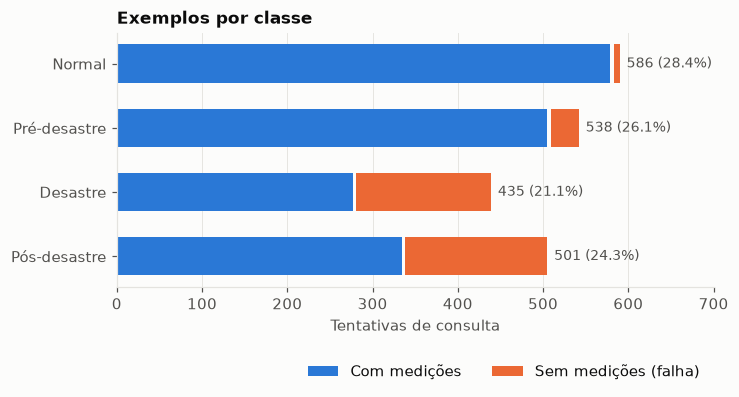

In [9]:
fig, ax = plt.subplots(figsize=(7, 3))
c = contagem.drop("Total")
nomes = [NOMES_CLASSES[k] for k in c.index]
ax.barh(nomes, c["com_medicoes"], color="#2a78d6", height=0.6, label="Com medições")
ax.barh(nomes, c["sem_medicoes"], left=c["com_medicoes"] + 4, color="#eb6834", height=0.6, label="Sem medições (falha)")
for i, (total, pct) in enumerate(zip(c["tentativas"], c["percentual"])):
    ax.text(total + 12, i, f"{int(total)} ({pct:.1f}%)", va="center", fontsize=9, color=TEXTO_SEC)
ax.invert_yaxis()
ax.set_xlabel("Tentativas de consulta")
ax.set_xlim(0, 700)
ax.grid(axis="y", visible=False)
ax.set_title("Exemplos por classe")
ax.legend(loc="lower right", ncols=2, bbox_to_anchor=(1, -0.42))
salvar(fig, "eda_classes.png")
plt.show()

A classe minoritária é `desastre` (cerca de 21%), e a majoritária é `normal` (cerca de 28%). O desbalanceamento é
moderado; não aplicamos reamostragem, mas usamos métricas macro (média simples entre classes) para que
`desastre` pese tanto quanto as demais.

As tentativas também se distribuem de modo diferente entre os dispositivos: os sensores com falha de rede (`d02`)
e degradação (`d03`, `d04`) acumulam menos tentativas no desastre por causa dos timeouts.

In [10]:
pd.crosstab([dados["papel"], dados["device_id"]], dados["label"])

label                       normal  pre_desastre  desastre  pos_desastre
papel            device_id                                              
Controle         gw01-d05       60            60        58            58
                 gw02-d05       58            58        59            57
Degradação       gw01-d03       56            54        37            45
                 gw01-d04       56            52        38            44
                 gw02-d03       58            50        40            40
                 gw02-d04       60            56        38            48
Falha de rede    gw01-d02       60            55        33            42
                 gw02-d02       58            46        29            47
Falha energética gw01-d01       60            51        51            60
                 gw02-d01       60            56        52            60

## 4. Comportamento ao longo do ciclo

Os gráficos abaixo mostram cada tentativa no tempo relativo de envio (`elapsed_s`), separando os dispositivos pelo
papel definido nos cenários. O tempo serve apenas para visualizar o roteiro; ele **não** será atributo do modelo.

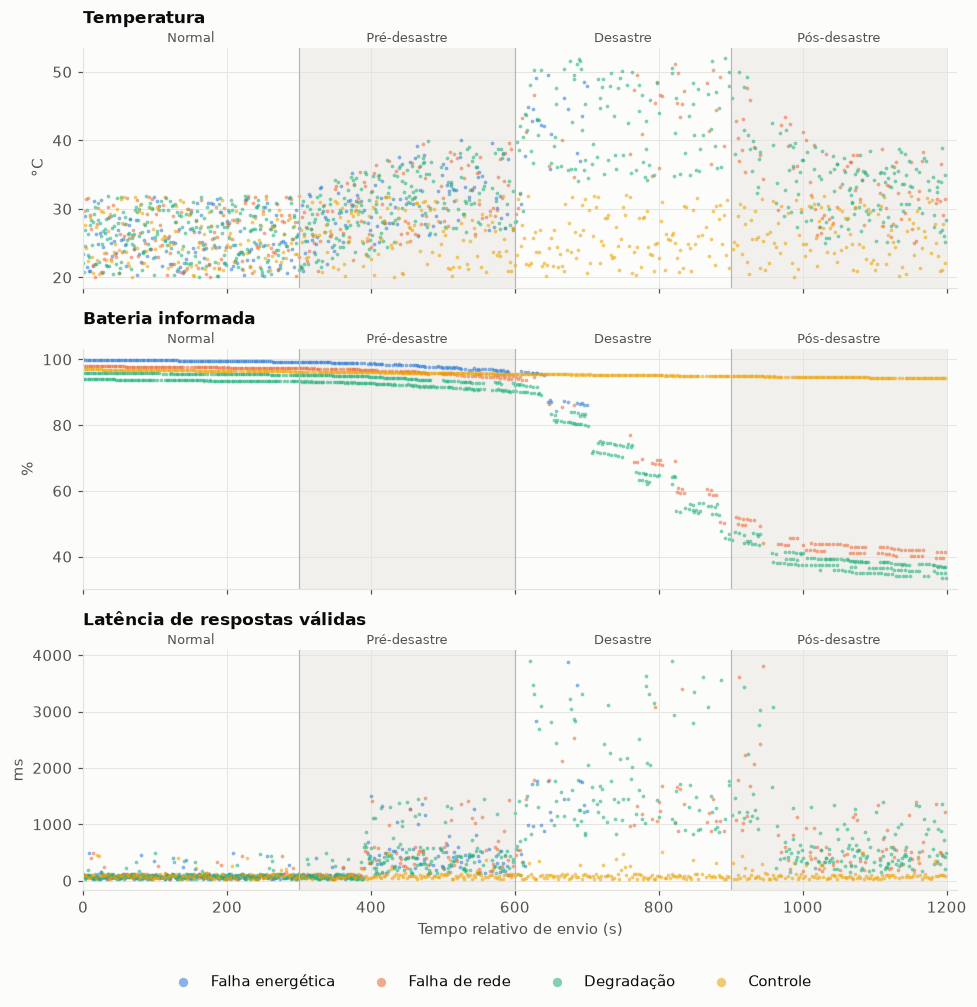

In [11]:
def series_por_papel(coluna, titulo, unidade, ax):
    for papel in ORDEM_PAPEIS:
        parte = dados[(dados["papel"] == papel) & dados[coluna].notna()]
        ax.scatter(parte["elapsed_s"], parte[coluna], s=6, alpha=0.55, color=COR_PAPEL[papel], lw=0, label=papel)
    sombrear_fases(ax)
    ax.set_ylabel(unidade)
    ax.set_title(titulo, pad=16)

fig, eixos = plt.subplots(3, 1, figsize=(9, 9), sharex=True)
series_por_papel("temperature", "Temperatura", "°C", eixos[0])
series_por_papel("battery", "Bateria informada", "%", eixos[1])
series_por_papel("latency_ms", "Latência de respostas válidas", "ms", eixos[2])
eixos[2].set_xlabel("Tempo relativo de envio (s)")
handles, labels = eixos[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncols=4, markerscale=2.5, bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=(0, 0.03, 1, 1))
salvar(fig, "eda_series_temporais.png")
plt.show()

Observações:

- **Temperatura**: a faixa sobe no pré-desastre e no desastre e cai parcialmente no pós-desastre, mas os controles
  (`d05`) permanecem entre 20 e 32 °C o tempo todo. Como a leitura é sorteada uniformemente na faixa vigente,
  as faixas das fases se sobrepõem bastante.
- **Bateria**: decresce de forma monotônica em todos os dispositivos e acelera depois do início do pré-desastre.
  `d01` deixa de responder pouco depois dos 690 s (esgotamento), `d02`, `d03` e `d04` terminam o ciclo entre
  33% e 43%, e os controles descem lentamente de ~97% para ~94%. Como a carga nunca aumenta, ela funciona quase
  como um **relógio** da execução — um ponto importante para interpretar os modelos.
- **Latência**: aumenta em degraus (pré-desastre a partir de ~390 s, desastre a partir de ~600 s) e recua no
  pós-desastre sem voltar ao normal.

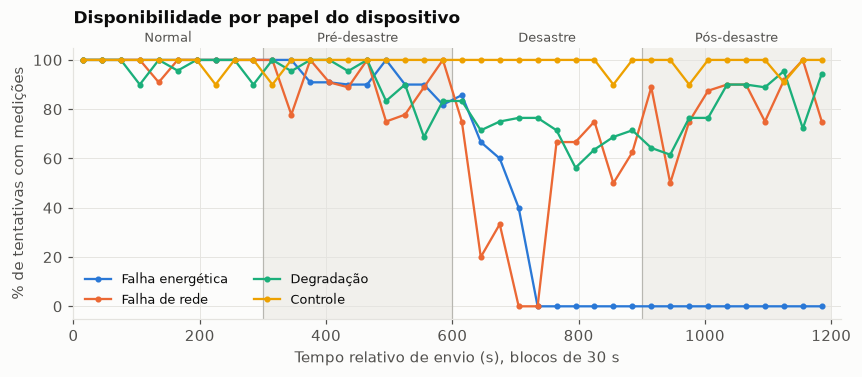

In [12]:
fig, ax = plt.subplots(figsize=(9, 3.2))
janela = dados.assign(bloco=(dados["elapsed_s"] // 30) * 30 + 15)
for papel in ORDEM_PAPEIS:
    serie = janela[janela["papel"] == papel].groupby("bloco")["available"].mean() * 100
    ax.plot(serie.index, serie.values, color=COR_PAPEL[papel], marker="o", ms=3, label=papel)
sombrear_fases(ax)
ax.set_ylim(-5, 105)
ax.set_ylabel("% de tentativas com medições")
ax.set_xlabel("Tempo relativo de envio (s), blocos de 30 s")
ax.set_title("Disponibilidade por papel do dispositivo", pad=16)
ax.legend(loc="lower left", ncols=2, fontsize=8.5)
salvar(fig, "eda_disponibilidade.png")
plt.show()

A disponibilidade confirma os efeitos programados: `d01` cai para zero após o esgotamento (respostas `5.03`),
`d02` fica sem resposta durante a interrupção de 60 s e depois se recupera, e `d03`/`d04` oscilam com a perda
de 35% no desastre. Os controles mantêm disponibilidade praticamente total.

## 5. Distribuição dos atributos por classe

In [13]:
atributos = SENSORES + BATERIA + REDE
dados.groupby("label", observed=True)[atributos].describe().T.loc[(slice(None), ["mean", "std", "min", "50%", "max"]), :]

label               normal  pre_desastre  desastre  pos_desastre
temperature mean  2.59e+01         29.57     35.33         31.18
            std   3.39e+00          4.59      9.64          5.81
            min   2.00e+01         20.01     20.27         20.03
            50%   2.58e+01         29.60     35.70         30.61
            max   3.19e+01         39.99     51.96         49.99
pressure    mean  1.01e+03       1009.85   1010.15       1010.19
            std   5.80e+00          5.66      5.76          6.00
            min   1.00e+03       1000.16   1000.13       1000.04
            50%   1.01e+03       1009.32   1010.37       1010.01
            max   1.02e+03       1019.97   1019.94       1019.96
battery     mean  9.67e+01         95.35     83.12         58.45
            std   2.01e+00          2.15     14.90         26.09
            min   9.33e+01         90.21     45.44         33.39
            50%   9.67e+01         95.76     91.65         42.47
            max   1.00e+02         99.26     96.34         94.93
latency_ms  mean  9.47e+01        294.23    992.61        499.58
            std   7.68e+01        316.67   1010.44        572.56
            min   2.48e+01         24.76     24.28         26.10
            50%   8.10e+01        156.14    889.60        342.04
            max   4.91e+02       1494.24   3904.69       3802.99
available   mean  9.88e-01          0.94      0.64          0.67
            std   1.09e-01          0.24      0.48          0.47
            min   0.00e+00          0.00      0.00          0.00
            50%   1.00e+00          1.00      1.00          1.00
            max   1.00e+00          1.00      1.00          1.00
drop_rate   mean  9.39e-03          0.05      0.33          0.35
            std   2.64e-02          0.07      0.33          0.38
            min   0.00e+00          0.00      0.00          0.00
            50%   0.00e+00          0.00      0.25          0.17
            max   8.33e-02          0.42      1.00          1.00

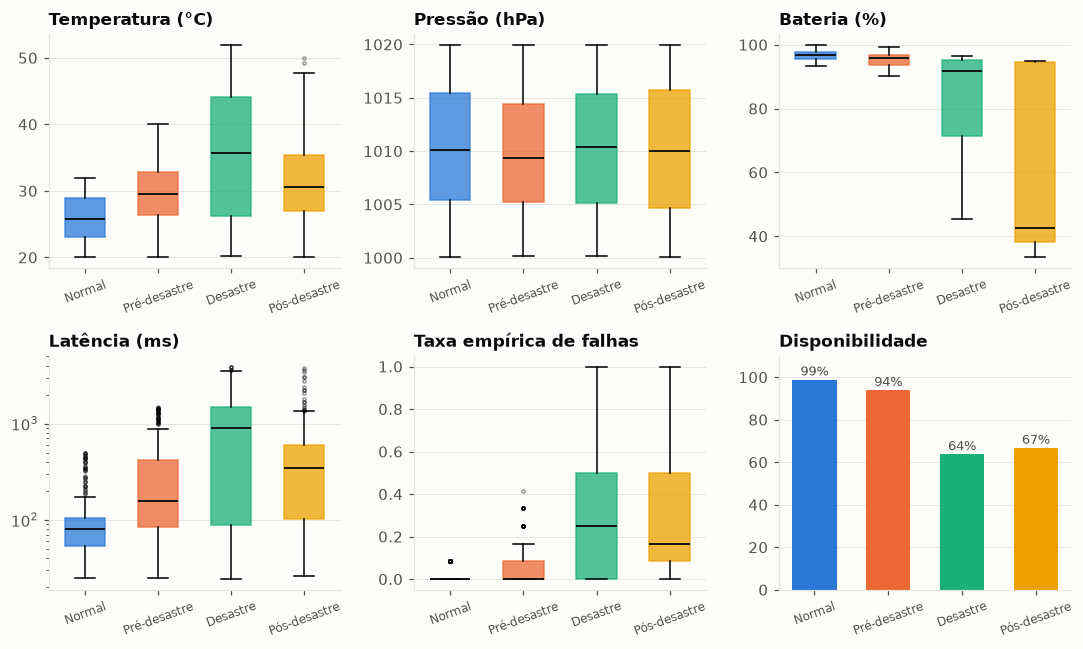

In [14]:
fig, eixos = plt.subplots(2, 3, figsize=(10, 6))
rotulos = [NOMES_CLASSES[k] for k in CLASSES]
for ax, (coluna, titulo) in zip(eixos.flat, [("temperature", "Temperatura (°C)"), ("pressure", "Pressão (hPa)"),
                                            ("battery", "Bateria (%)"), ("latency_ms", "Latência (ms)"),
                                            ("drop_rate", "Taxa empírica de falhas"), ("available", "Disponibilidade")]):
    if coluna == "available":
        valores = dados.groupby("label", observed=True)["available"].mean() * 100
        ax.bar(rotulos, valores, color=[COR_CLASSE[k] for k in CLASSES], width=0.6)
        for i, v in enumerate(valores):
            ax.text(i, v + 2, f"{v:.0f}%", ha="center", fontsize=8.5, color=TEXTO_SEC)
        ax.set_ylim(0, 110)
    else:
        grupos = [dados.loc[dados["label"] == k, coluna].dropna() for k in CLASSES]
        caixa = ax.boxplot(grupos, tick_labels=rotulos, patch_artist=True, widths=0.55,
                           medianprops={"color": "#0b0b0b", "lw": 1.2}, flierprops={"ms": 2, "alpha": 0.4})
        for patch, k in zip(caixa["boxes"], CLASSES):
            patch.set(facecolor=COR_CLASSE[k], alpha=0.75, edgecolor=COR_CLASSE[k])
    if coluna == "latency_ms":
        ax.set_yscale("log")
    ax.set_title(titulo)
    ax.tick_params(axis="x", labelsize=8, rotation=20)
    ax.grid(axis="x", visible=False)
fig.tight_layout()
salvar(fig, "eda_distribuicoes.png")
plt.show()

- **Pressão** tem a mesma distribuição nas quatro classes (faixa fixa 1000–1020 hPa por construção do cenário):
  não deve ajudar o classificador.
- **Temperatura** separa razoavelmente `normal` de `desastre`, mas `pre_desastre` e `pos_desastre` se sobrepõem
  quase completamente, e há leituras normais em todas as fases por causa dos controles.
- **Bateria** separa bem `normal`/`pre_desastre` (alta) de `pos_desastre` (mediana baixa), porque registra o
  consumo acumulado.
- **Latência**, **disponibilidade** e **taxa de falhas** distinguem `normal` das fases degradadas, mas não
  separam bem `desastre` de `pos_desastre`.

Nenhum atributo isolado separa as quatro classes: espera-se que a combinação de sensores, rede e bateria seja
necessária.

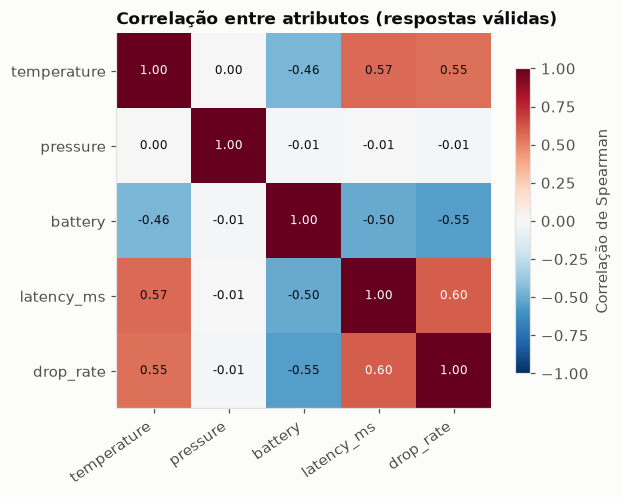

In [15]:
continuos = ["temperature", "pressure", "battery", "latency_ms", "drop_rate"]
validas = dados[dados["available"] == 1]
correlacao = validas[continuos].corr(method="spearman")
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(correlacao, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(continuos)), continuos, rotation=35, ha="right")
ax.set_yticks(range(len(continuos)), continuos)
for i in range(len(continuos)):
    for j in range(len(continuos)):
        v = correlacao.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(v) > 0.6 else "#0b0b0b")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="Correlação de Spearman")
ax.set_title("Correlação entre atributos (respostas válidas)")
salvar(fig, "eda_correlacao.png")
plt.show()

As correlações usam apenas as respostas válidas (`available = 1`), onde todas as medições existem; por isso `available`, constante nesse subconjunto, fica de fora. A relação dela com a rede aparece na correlação negativa com `drop_rate` ao longo de todas as tentativas. Latência e taxa de falhas andam juntas (ambas
refletem a degradação da rede), e a bateria correlaciona-se negativamente com ambas, pois o consumo é maior
justamente nos períodos degradados. A pressão é independente de tudo.

## 6. Implicações para a modelagem

1. **Ausências informativas.** As falhas não podem ser descartadas (são parte do fenômeno) nem convertidas em zero.
   No notebook de modelos, as medições ausentes são imputadas pela mediana do treino, e `available` informa ao
   modelo que a tentativa falhou.
2. **Remover duas linhas** com `cruzou_fase = 1`; manter as transições (`em_transicao`) apenas para análise de erros.
3. **Atributos permitidos:** `temperature`, `pressure`, `battery`, `latency_ms`, `available`, `drop_rate`.
   Tempo, eventos, códigos CoAP, identificadores e coordenadas ficam fora para não entregar o roteiro ao modelo.
4. **Bateria como relógio.** Em uma única execução, a carga decresce monotonicamente e acaba codificando o tempo
   decorrido. Um bom desempenho apoiado na bateria pode não se repetir em execuções com outras cargas iniciais.
5. **Controles e sobreposição.** Leituras de controle durante o desastre são idênticas às do estado normal; um
   classificador por linha não tem como acertá-las. Isso limita a acurácia máxima atingível sem agregação temporal
   ou entre dispositivos.
6. **Uma única execução.** Linhas vizinhas no tempo são muito parecidas. Uma divisão aleatória treino/teste mistura
   instantes quase idênticos e tende a superestimar o desempenho; por isso, o próximo notebook também avalia uma
   divisão por gateway (dispositivos diferentes, mesmos papéis).